In [2]:
# -------------------- 1 ----------------------

import xarray as xr
import numpy as np
import pandas as pd

import optuna

from lightgbm import LGBMRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from sklearn.model_selection import KFold

from optuna.samplers import TPESampler

In [3]:
# ---------- 2 ------------

df = pd.read_parquet("/home/prasanna/Ishan/ACRI_Data_Prep_Analysis/final_training_ACRI_1998_2025.parquet")

# -----------------------------
# Western Arabian Sea
# Lon: 45°E–65°E
# Lat: 5°N–28°N
# -----------------------------

df = df[
    (df["longitude"] >= 45) &
    (df["longitude"] <= 65) &
    (df["latitude"]  >= 5) &
    (df["latitude"]  <= 25)
].copy()

print(f"Total samples in Western Arabian Sea = {len(df):,}")

TARGET = "chlor_a_log10"

DROP_COLS = [
    TARGET,
    "latitude",
    "longitude",
    "Year",
    "Month",
    "zos",
    "grad_ssh"
]

# -----------------------------
# Train : 1998–2023
# Test  : 2024–2025
# -----------------------------

train_df = df[
    (df["Year"] >= 1998) &
    (df["Year"] <= 2023)
].copy()

test_df = df[
    (df["Year"] >= 2024) &
    (df["Year"] <= 2025)
].copy()

train_df = train_df.sort_values(
    ["Year", "Month"]
).reset_index(drop=True)

test_df = test_df.sort_values(
    ["Year", "Month"]
).reset_index(drop=True)

FEATURES = [
    col for col in df.columns
    if col not in DROP_COLS
]

X_train = train_df[FEATURES].astype("float32")
y_train = train_df[TARGET].astype("float32")

X_test = test_df[FEATURES].astype("float32")
y_test = test_df[TARGET].astype("float32")

print(f"Training samples : {len(X_train):,}")
print(f"Testing samples  : {len(X_test):,}")
print(f"Number of features : {len(FEATURES)}")

Total samples in Western Arabian Sea = 11,835,586
Training samples : 10,990,036
Testing samples  : 845,550
Number of features : 10


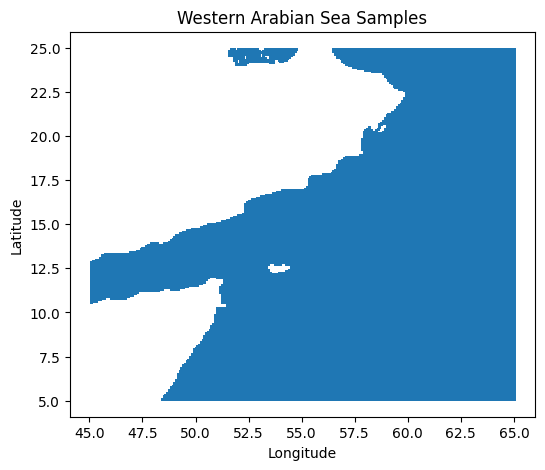

In [4]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.scatter(
    df["longitude"],
    df["latitude"],
    s=0.1,
    alpha=0.2
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Western Arabian Sea Samples")
plt.show()

In [5]:

print(train_df.shape)
print(test_df.shape)



(10990036, 16)
(845550, 16)


In [6]:
# --------- 3 --------------

# ============================================================
# Standard K-Fold Cross Validation
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_indices = list(kf.split(X_train))

# ============================================================
# Check Folds
# ============================================================

for i, (train_idx, valid_idx) in enumerate(fold_indices, start=1):

    print(f"\nFold {i}")

    print(
        f"Train Samples: {len(train_idx):,}"
    )

    print(
        f"Valid Samples: {len(valid_idx):,}"
    )


Fold 1
Train Samples: 8,792,028
Valid Samples: 2,198,008

Fold 2
Train Samples: 8,792,029
Valid Samples: 2,198,007

Fold 3
Train Samples: 8,792,029
Valid Samples: 2,198,007

Fold 4
Train Samples: 8,792,029
Valid Samples: 2,198,007

Fold 5
Train Samples: 8,792,029
Valid Samples: 2,198,007


In [7]:
# ----------------- 4 --------------------------

def make_underestimation_loss(under_penalty):

    def underestimation_loss(y_true, y_pred):

        error = y_true - y_pred

        grad = np.where(
            error > 0,
            -2.0 * (1.0 + under_penalty) * error,
            -2.0 * error
        )

        hess = np.where(
            error > 0,
            2.0 * (1.0 + under_penalty),
            2.0
        )

        return grad, hess

    return underestimation_loss

In [8]:
# -------------- 5 ----------------------

def objective(trial):


    under_penalty = 3.5

    custom_loss = make_underestimation_loss(
        under_penalty
    )

    max_depth = trial.suggest_int(
        "max_depth",
        30,
        50
    )

    max_leaves_allowed = min(
        2 ** max_depth,
        1200
    )

    params = {

        "max_depth": max_depth,

        "num_leaves": trial.suggest_int(
            "num_leaves",
            30,
            max_leaves_allowed
        ),

        "n_estimators": trial.suggest_int(
            "n_estimators",
            500,
            800
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.001,
            0.30,
            log=True
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.650,
            0.900
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.65,
            1.0
        ),

        "min_child_samples": trial.suggest_int(
            "min_child_samples",
            25,
            45
        ),

        "min_split_gain": trial.suggest_float(
            "min_split_gain",
            0.8,
            2.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha",
            0.007,
            1.0,
            log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda",
            12,
            35,
            log=True
        ),

        "device": "gpu",
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1
    }

    fold_r2 = []
    fold_rmse = []
    fold_mae = []
    fold_bias = []

    for train_idx, valid_idx in fold_indices:

        X_tr = X_train.iloc[train_idx]
        y_tr = y_train.iloc[train_idx]

        X_val = X_train.iloc[valid_idx]
        y_val = y_train.iloc[valid_idx]

        model = LGBMRegressor(
            objective=custom_loss,
            **params
        )

        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_val, y_val)]
        )

        pred = model.predict(X_val)

        r2 = r2_score(y_val, pred)

        rmse = np.sqrt(
            mean_squared_error(y_val, pred)
        )

        mae = mean_absolute_error(
            y_val,
            pred
        )

        bias = np.mean(
            pred - y_val
        )

        fold_r2.append(r2)
        fold_rmse.append(rmse)
        fold_mae.append(mae)
        fold_bias.append(bias)

    mean_r2 = np.mean(fold_r2)
    mean_rmse = np.mean(fold_rmse)
    mean_mae = np.mean(fold_mae)
    mean_bias = np.mean(fold_bias)

    trial.set_user_attr("cv_r2", mean_r2)
    trial.set_user_attr("cv_rmse", mean_rmse)
    trial.set_user_attr("cv_mae", mean_mae)
    trial.set_user_attr("cv_bias", mean_bias)

    return mean_rmse



In [9]:
# ----------- 6 ---------------

study = optuna.create_study(
    direction="minimize",
    study_name="LGBM_ChlA",
    sampler=optuna.samplers.TPESampler(
        seed=42,
        multivariate=True,
        group=True
    )
    
)

study.optimize(
    objective,
    n_trials=20,
    show_progress_bar=True,
    n_jobs= -1
)

/home/prasanna/anaconda3/envs/mlenv/lib/python3.10/site-packages/optuna/samplers/_tpe/sampler.py:282: ExperimentalWarning: ``multivariate`` option is an experimental feature. The interface can change in the future.
  warnings.warn(
/home/prasanna/anaconda3/envs/mlenv/lib/python3.10/site-packages/optuna/samplers/_tpe/sampler.py:293: ExperimentalWarning: ``group`` option is an experimental feature. The interface can change in the future.
  warnings.warn(
[I 2026-07-31 20:06:45,392] A new study created in memory with name: LGBM_ChlA
/home/prasanna/anaconda3/envs/mlenv/lib/python3.10/site-packages/optuna/progress_bar.py:56: ExperimentalWarning: Progress bar is experimental (supported from v1.2.0). The interface can change in the future.
  self._init_valid()


  0%|          | 0/20 [00:00<?, ?it/s]

[I 2026-07-31 20:39:55,735] Trial 17 finished with value: 0.18510033726342753 and parameters: {'max_depth': 41, 'num_leaves': 1012, 'n_estimators': 528, 'learning_rate': 0.17718457051662584, 'subsample': 0.7777663589951176, 'colsample_bytree': 0.842170601827573, 'min_child_samples': 29, 'min_split_gain': 1.7305586399616826, 'reg_alpha': 0.1975988394447484, 'reg_lambda': 21.858138267111908}. Best is trial 17 with value: 0.18510033726342753.
[I 2026-07-31 20:42:57,360] Trial 4 finished with value: 0.1854063894627654 and parameters: {'max_depth': 37, 'num_leaves': 823, 'n_estimators': 583, 'learning_rate': 0.12224032353241555, 'subsample': 0.6745770877351969, 'colsample_bytree': 0.974331866741333, 'min_child_samples': 39, 'min_split_gain': 1.8893640667992218, 'reg_alpha': 0.03402133677383616, 'reg_lambda': 30.21272894476004}. Best is trial 17 with value: 0.18510033726342753.
[I 2026-07-31 20:46:13,707] Trial 11 finished with value: 0.18726392947415507 and parameters: {'max_depth': 41, 'nu

[I 2026-07-31 21:38:06,624] Trial 16 finished with value: 0.20943819005599956 and parameters: {'max_depth': 32, 'num_leaves': 740, 'n_estimators': 581, 'learning_rate': 0.004246914554105416, 'subsample': 0.6681107108809533, 'colsample_bytree': 0.6533201713864465, 'min_child_samples': 40, 'min_split_gain': 1.0050328018865289, 'reg_alpha': 0.13689956475084303, 'reg_lambda': 20.73130172463182}. Best is trial 14 with value: 0.18207748607571425.
[I 2026-07-31 21:38:38,082] Trial 7 finished with value: 0.18098656116464357 and parameters: {'max_depth': 36, 'num_leaves': 977, 'n_estimators': 549, 'learning_rate': 0.016219994851577477, 'subsample': 0.8506101511488265, 'colsample_bytree': 0.8861597491324742, 'min_child_samples': 34, 'min_split_gain': 1.264546423523391, 'reg_alpha': 0.6724176588245641, 'reg_lambda': 26.482640903678917}. Best is trial 7 with value: 0.18098656116464357.


In [10]:
# -------------- 7 --------------

best_trial = study.best_trial

print("\nBest Mean CV R² :", best_trial.user_attrs["cv_r2"])
print("Best Mean CV RMSE:", best_trial.user_attrs["cv_rmse"])
print("Best Mean CV MAE :", best_trial.user_attrs["cv_mae"])
print("Best Mean CV Bias:", best_trial.user_attrs["cv_bias"])

print("\nBest Parameters:")
for k, v in study.best_params.items():
    print(f"{k}: {v}")


Best Mean CV R² : 0.7923504785001498
Best Mean CV RMSE: 0.18098656116464357
Best Mean CV MAE : 0.13625404880855663
Best Mean CV Bias: 0.08609509262569263

Best Parameters:
max_depth: 36
num_leaves: 977
n_estimators: 549
learning_rate: 0.016219994851577477
subsample: 0.8506101511488265
colsample_bytree: 0.8861597491324742
min_child_samples: 34
min_split_gain: 1.264546423523391
reg_alpha: 0.6724176588245641
reg_lambda: 26.482640903678917


In [11]:
# ------------ 8 ---------------

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ============================================================
# Extract tuned under_penalty            
# ============================================================

best_model_params = study.best_params.copy()

#best_under_penalty = 3.5

custom_loss = make_underestimation_loss(
    best_under_penalty
)

results = []

for fold, (train_idx, valid_idx) in enumerate(
    fold_indices,
    start=1
):

    X_tr = X_train.iloc[train_idx]
    y_tr = y_train.iloc[train_idx]

    X_val = X_train.iloc[valid_idx]
    y_val = y_train.iloc[valid_idx]

    model = LGBMRegressor(
        objective=custom_loss,
        device="gpu",
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        **best_model_params
    )

    model.fit(
        X_tr,
        y_tr
        #verbose=False
    )

    # ----------------------------------
    # Train Metrics
    # ----------------------------------

    pred_train = model.predict(X_tr)

    train_r2 = r2_score(
        y_tr,
        pred_train
    )

    train_rmse = np.sqrt(
        mean_squared_error(
            y_tr,
            pred_train
        )
    )

    train_mae = mean_absolute_error(
        y_tr,
        pred_train
    )

    train_bias = np.mean(
        pred_train - y_tr
    )

    # ----------------------------------
    # Validation Metrics
    # ----------------------------------

    pred_val = model.predict(X_val)

    val_r2 = r2_score(
        y_val,
        pred_val
    )

    val_rmse = np.sqrt(
        mean_squared_error(
            y_val,
            pred_val
        )
    )

    val_mae = mean_absolute_error(
        y_val,
        pred_val
    )

    val_bias = np.mean(
        pred_val - y_val
    )

    print(f"\nFold {fold}")

    print(
        f"TRAIN      | "
        f"R²={train_r2:.5f} | "
        f"RMSE={train_rmse:.5f} | "
        f"MAE={train_mae:.5f} | "
        f"Bias={train_bias:.5f}"
    )

    print(
        f"VALIDATION | "
        f"R²={val_r2:.5f} | "
        f"RMSE={val_rmse:.5f} | "
        f"MAE={val_mae:.5f} | "
        f"Bias={val_bias:.5f}"
    )

    results.append([
        fold,
        train_r2,
        val_r2,
        train_rmse,
        val_rmse,
        train_mae,
        val_mae,
        train_bias,
        val_bias
    ])

# ============================================================
# Fold-wise Metrics
# ============================================================

cv_metrics_df = pd.DataFrame(
    results,
    columns=[
        "Fold",
        "Train_R2",
        "Val_R2",
        "Train_RMSE",
        "Val_RMSE",
        "Train_MAE",
        "Val_MAE",
        "Train_Bias",
        "Val_Bias"
    ]
)

print("\n")
print(cv_metrics_df)

# ============================================================
# Mean Metrics
# ============================================================

summary_df = pd.DataFrame({

    "Metric": [
        "R2",
        "RMSE",
        "MAE",
        "Bias"
    ],

    "Train_Mean": [

        cv_metrics_df["Train_R2"].mean(),
        cv_metrics_df["Train_RMSE"].mean(),
        cv_metrics_df["Train_MAE"].mean(),
        cv_metrics_df["Train_Bias"].mean()
    ],

    "Validation_Mean": [

        cv_metrics_df["Val_R2"].mean(),
        cv_metrics_df["Val_RMSE"].mean(),
        cv_metrics_df["Val_MAE"].mean(),
        cv_metrics_df["Val_Bias"].mean()
    ]
})

print(summary_df)

# ============================================================
# CV Mean ± Std Summary
# ============================================================

cv_stats_df = pd.DataFrame({

    "Metric": [
        "R2",
        "RMSE",
        "MAE",
        "Bias"
    ],

    "Train_Mean": [

        cv_metrics_df["Train_R2"].mean(),
        cv_metrics_df["Train_RMSE"].mean(),
        cv_metrics_df["Train_MAE"].mean(),
        cv_metrics_df["Train_Bias"].mean()
    ],

    "Train_SD": [

        cv_metrics_df["Train_R2"].std(),
        cv_metrics_df["Train_RMSE"].std(),
        cv_metrics_df["Train_MAE"].std(),
        cv_metrics_df["Train_Bias"].std()
    ],

    "Validation_Mean": [

        cv_metrics_df["Val_R2"].mean(),
        cv_metrics_df["Val_RMSE"].mean(),
        cv_metrics_df["Val_MAE"].mean(),
        cv_metrics_df["Val_Bias"].mean()
    ],

    "Validation_SD": [

        cv_metrics_df["Val_R2"].std(),
        cv_metrics_df["Val_RMSE"].std(),
        cv_metrics_df["Val_MAE"].std(),
        cv_metrics_df["Val_Bias"].std()
    ]
})

print("\nCross-Validation Mean ± SD")
print(cv_stats_df)

# ============================================================
# Best Custom Loss Parameter
# ============================================================

print(
    f"\nBest under_penalty: "
    f"{best_under_penalty:.6f}"
)

NameError: name 'best_under_penalty' is not defined

In [ ]:
# --------------- 9 ------------------

# ============================================================
# Extract Best Tuned under_penalty
# ============================================================

best_model_params = study.best_params.copy()

best_under_penalty = 3.5


custom_loss = make_underestimation_loss(
    best_under_penalty
)

# ============================================================
# Final Model Training
# ============================================================

final_model = LGBMRegressor(
    objective=custom_loss,
#     device="gpu",
    verbosity=-1,
    random_state=42,
    n_jobs=-1,
    **best_model_params
)

final_model.fit(
    X_train,
    y_train
    #verbose=False
)

print("\nFinal model trained successfully.")

print(
    f"Best under_penalty = "
    f"{best_under_penalty:.6f}"
)

In [ ]:
# ------------------ 9 ----------------------

import joblib

# ============================================================
# Save Final Model
# ============================================================

MODEL_PATH = "ACRI_LGBM_WAS_Tuned_model_1.pkl"

joblib.dump(
    final_model,
    MODEL_PATH
)

print("\n" + "="*60)
print("MODEL SAVED SUCCESSFULLY")
print("="*60)
print(f"Saved as: {MODEL_PATH}")